# Module 8 — Efficient Fine-Tuning and Data Engineering

## Lesson 8.4 — The Fine-Tuning Workflow


Note 8.1 gave a quick look at full fine-tuning; Note 8.2 prepared the data; Note 8.3 set the bar. Now we fine-tune properly, taking the workflow apart one step at a time: loading a pretrained model with a new classification head, feeding it inputs, labels and masks, computing the loss, taking a gradient step, choosing the learning rate and schedule, selecting a checkpoint on validation, and saving the result.

Most of this will feel familiar. It is the same training loop you wrote in Module 2, now running on a Transformer with tens of millions of parameters that starts out already knowing English. The differences are in the details: a much smaller learning rate, warmup, gradient clipping, and careful checkpoint selection. We'll write the loop ourselves first, then run the same recipe with Hugging Face's `Trainer`, which hides the loop, and check that the two agree. Finally we test the model once and compare it, review by review, with the baselines from Note 8.3.

**Key question:** *What exactly happens when we fine-tune a pretrained model, and how do we do it reliably?*

### Learning objectives
- load a pretrained model with a new classification head and explain what the LOAD REPORT means;
- compute a classification loss by hand and match the model's own loss;
- explain one optimisation step: gradients, clipping and the update;
- choose a learning rate, batch size, number of epochs and warmup, and explain why fine-tuning uses small learning rates;
- select a checkpoint on validation;
- fine-tune with a custom loop and with the Hugging Face `Trainer`, save and reload the result, and evaluate it against baselines.

### Prerequisites

 read Notes 8.1–8.3. You'll use the training loop from Module 2, learning-rate schedules and gradient clipping from Module 3 and Note 6.6, the classification head and LOAD REPORT from Note 7.1, and padding and attention masks from Note 7.4.

### Setup

The usual imports, seeds and device check, and the same harmless warnings as before. Two more appear in this note: the LOAD REPORT when a classification head is added (Section 2), and a progress bar while the `Trainer` runs. **This is the longest-running notebook in the module.** It trains the model twice, once with our own loop and once with the `Trainer`, which takes a couple of minutes on a fast laptop CPU and longer on a slower one. With a GPU (for example on Google Colab), the setup cell picks it up automatically and the training takes seconds.

**Environment and reference results.** Use Python 3.12 and [requirements.txt](../static/notebook-support/module78/requirements.txt) (also supplied at the root of the Module 7/8 notebook bundle). Install packages into a separate environment, restart the kernel, and run from the beginning. The saved outputs are the author's CPU reference run, with approved explanatory corrections. Seeds and artifact revisions reduce variation; numbers and timings can differ across hardware. No account or paid API is required for the public teaching models. Initial model/data downloads require internet access.

**Comparison artifacts.** Missing baseline result files are restored from bundled, clearly labelled author reference data. Existing result files are preserved. Run 8.3–8.5 in the same working folder to replace these with your own experiments. The encoded reference payload in setup is delivery data; you do not need to decipher it to study the model code.

In [1]:
import os, json, time, copy, math, shutil, hashlib
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset, Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, AutoModelForMaskedLM,
                          DataCollatorWithPadding, TrainingArguments, Trainer, get_linear_schedule_with_warmup)

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

# Freeze the public artifacts used by the recorded experiments.
MODEL_REVISIONS = {'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'distilbert/distilbert-base-uncased-finetuned-sst-2-english': '714eb0fa89d2f80546fda750413ed43d93601a13', 'sentence-transformers/all-MiniLM-L6-v2': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'HuggingFaceTB/SmolLM2-135M': '93efa2f097d58c2a74874c7e644dbc9b0cee75a2', 'distilbert/distilgpt2': '2290a62682d06624634c1f46a6ad5be0f47f38aa', 'HuggingFaceTB/SmolLM2-135M-Instruct': '12fd25f77366fa6b3b4b768ec3050bf629380bac', 'HuggingFaceTB/SmolLM2-360M-Instruct': 'a10cc1512eabd3dde888204e902eca88bddb4951', 'Qwen/Qwen2.5-0.5B': '060db6499f32faf8b98477b0a26969ef7d8b9987', 'Qwen/Qwen2.5-7B': 'd149729398750b98c0af14eb82c78cfe92750796', 'google-bert/bert-large-uncased': '6da4b6a26a1877e173fca3225479512db81a5e5b', 'distilbert/distilbert-base-uncased': '12040accade4e8a0f71eabdb258fecc2e7e948be', 'google-bert/bert-base-uncased': '86b5e0934494bd15c9632b12f734a8a67f723594', 'cardiffnlp/twitter-roberta-base-sentiment-latest': '3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7', 'distilbert/distilbert-base-cased-distilled-squad': '564e9b582944a57a3e586bbb98fd6f0a4118db7f', 'google/vit-base-patch16-224': '3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3', 'sshleifer/distilbart-cnn-12-6': 'a4f8f3ea906ed274767e9906dbaede7531d660ff', 'textattack/distilbert-base-uncased-imdb': '5b0f46c2fc4b86bf21f0ec0409bed77ee142b332', 'google/gemma-2-2b': 'c5ebcd40d208330abc697524c919956e692655cf', 'meta-llama/Llama-3.2-1B': '4e20de362430cd3b72f300e6b0f18e50e7166e08'}
DATASET_REVISIONS = {'stanfordnlp/imdb': 'e6281661ce1c48d982bc483cf8a173c1bbeb5d31', 'stanfordnlp/sst2': '8d51e7e4887a4caaa95b3fbebbf53c0490b58bbb'}

def benchmark_clock():
    """Read elapsed time after completing any queued CUDA work."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    import time
    return time.perf_counter()

def ordered_fingerprint(texts, labels):
    """Hash ordered text/label pairs so paired predictions cannot be silently misaligned."""
    import json, hashlib
    rows = [[str(t), int(y)] for t, y in zip(texts, labels)]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(',', ':')).encode()).hexdigest()

# Author reference results are embedded for standalone downloads, never fetched secretly.
REFERENCE_RESULTS_GZIP = 'H4sIAAAAAAAC/+1bbW/bOBL+K4I/7aGJb4YvEpVFP9zt3gIH3KfdfisKQ3HkxFe/nay01y3y35ccWY4tzVByWizugEBoStMUhxy+Pc8z9NeJm+rJzdfJZluXkxv6dDXZ71bLerZYbu7LalctN/U+FKmrYrnxZRa3ukCl8kVu0Rf+VKxmpf/jv8lzbRaLsijmefimLvd1+9Vini+K3GWAt/PJ01VT2Wz/eLsvzyz5otktzAsLiP4/X0v1uLkn++vi39tqWX9J5qtiTzlU9ddJMZ8/VsX8y+QGphasf6WcF6vVbFPeT25wCseM3XYfyviMBR4/PDUN7VZk3AsqWhW35Wo/e9yXd/4FADg4YVeFjPdw9fq8Pq/P6/P6vD6vz//588Gf+O9+uf7nz79cJXjlT/ukOf8FaOLS9BxRhKxcd0GFS1V6iitcaoyAUZxyvRoVpL0atT2rUGv91Acm6J/nv3D4i8fu4tm/0++w9/k09/R7PMkF5juprn47ztuJZ/bgzEbfIpy0DJgeYbT/wNTX9wP2bPTbyPen7yupRLcf3fqwNxLQGzXs+aTbUzwb+W5/oOP1buu7b0vzB5hec77nesD5i289Z/XcT9K4oOiXvmf6be36BNgV0e251FKM+DG2hrm1B2x7QBwBfsy4OcrtGtBbX9yaA2YvQGY8JJ8AM6tRGAlpD4uNH7C7GfbWGbL1Itu6WJ8hMkuwt44hMsIojl9330R2lqHQcxDHE3rrq7t/SiXk8eH2tf6ezZ8A8g6OvXHn5y6IZwdGdyZux4Veb1E4Lbn1CMyu0gATXokIkkt5N9sVVbEu67LyaEDlmbWtGlMv10EDgikm+6AClXW93HhUMfnprZ6cYB0PLeJIJ1fYxSU5OtfFJbnS6hSY5AokpJOj7teY95BODqk7qxGNi0IdHDH4KBw5MHiYSFMYWSgEkW2/v7ik5ctPTm4j45YNN6kvhTr9XGSnqryRwsDWw/kcxS34EqgjbSFxqAMRqCOBrjg84noAEajT3+T4g56HOhJ4GII6IGyjKGxeyMy3GNTBAfgk9xqFLZ7floehTt8ODkIe6K0i+aDkoT4yM0CiJMAABGAPFhDBAog943cynhZx+wa/M/EwHQUg/GdAHc6nQ1CHm4089QKWjnxvqMP5ZSzUgcjuhSKNRYHGx85PZCE9smfNBVBHKQOGxzo6z43FDtgxU9MDOwgB7fz227trlay3d+XqKtkuFkn9UCb7h3K1kPQd11djXI49Ncal+Zkc4z9L+k7WQz3O2qxfY1CRTmrMnBJQDzJ4ASPCiizwxIAvd/pAZOUCczJx5BQYcQAjAg8OCjw8eZQRkrwTYYTMS6gHWNHi21GPJPCAiA6BlQxQpKHIID9kdgsJ9ch2gB0PEBEzslIDsLMGIoIcChiZf1Oi+cDOY36+yeIiPx9hJJGUcJ8sxvIoZmh34BAgRmUsEEaclznkUZJ2Cp5hyagHhVrGoB4U9xh+nkFULkJBlJIYFgj4HFmkEcuNISaJ5UIU48joW94VYQS6x6gMP7QrAHtKgMA6L0E9GEE9GEE98ALUc/imi3oEdcdnLzeLsio384B1co911vtkV1ZJVX5alp/PcM9DWdy9qYulRzuoXFJvP5abfQBCi2r7e7lJfl7u6+Xq7//49V3yJllt78PHua/ovir3++V2I6Ei24cwuelBGEJtJxDGZFoCRTrr1ahtH2Zp585rRB0BRWN1wKGolzRRMRIRkyczCouHF26Go17wQikIBqEhd1zDiCgQRhca3zsplvYyUCQt6TGgSI56ST6X35MjR5LUKEUtZKguCSz8cSNLnyi2SxpHFCK4MCCa8aAILwRFIESLZdkW2LWArAAjxQ1R8DwvcsryniSkShFHHC0FISsY8IQIBC8jS134PQYEMQujImtcNpYBQFwKkmCYdC+Ap4WxGCxGaINMOoelIBgFisaDMmBl/XGgSBovGA2KeFLPg04OTj1fxxkd9cqCAnMmA+VT3ZGB1mWxSXbb7cp/vEqO4Chgo6vkp7c4eXrycMJNzdntaePr8FYetnfhzvPjapUsvPXr+nHjq0l+mD/u6+3ao6ft7iqZP2z3HlfNH8r5x912uan/8r929frgjeb2dRDCfJE7goG3ZVX/9Tl5fVvsy+vHzbwInvcuKP47W5Wb+/rBD0O4pFRX4cuaYOIz0vQly912/uANePx2W9Tzh9l++bt3JaZ+MMuiCm6bVUXwri2vw93uz0W1ftwFROdfua+Ku9l8tdwdrmc3Lp3t69LnUOhPmhHF7ao8mxNpmlvfc+hMjLSJhVJeaMu6XG+rLzPv3uXaN2u2vg3VZnjF3/gSMazpYdjMqC6GzfIUz29uYTqAYWHw5haINzGk8y4ubfOoAAYCK8jugWNvbsmSfQzDysiPP9HidBgjGBbFu0cY3T0hIjnIGBa+SdiDEcKeHLoZDkpCNFw+RtiD6M0tKYgu38+6TNiTAqRjwpmS90EU4HBAQOX4DoiCJwprGgcwLM9E+ZCkdO+HQ1Ag3CwEAVePDWditMVjhD1gg5GyvAUjBDm+PpkFSYG7MeFMaQ7GhL3xGHYo8AuDtzDHhDO58ZTD8t8Dw4IgnGJEXAbxru2QsCfpRyf5HsMuttV9g7tmn7fV3ez+Mehr/tNq2/zqzZ/8B1A7udFT7QJEOIDMkGWmkB1RXnhn5nHHJ49l3r/3Jqapy9yHq/cqJHPMfVL7pAeHIWmaAiFpKVeHZEplHfpkFpJZbnzSNWV9Kg9FkTI9fgpllQppMpdmlCZ7BigdDKaodUiTxUyHujGYtGmoEcmk0jakg82MKieTGYb2YzBqNaShL8GopVYrshkKK7LoUV1Ia6qZXlTBonUQzCiyiFRHsGicCRZVsGiNCg1Ujoo7SgebxsPv4DSy6bLQcB2MWpWFd7WiMobKBLMGyawOZpX3eEiTWd2USakeTWWCXY0YnKSDXZM1ZaivmIcmm2BX62a0yG5G7TTBrs7JY4a6m1PSUDUuVG+CWZWTgw11l6yajFpGPTeOaqckGc2zULkNRo0NbbfBps6o35Zsogr+s42LgfKpr1mwY4NNA5aKBJvaAM2ujPJd6Kolo5ml/GA1BbKa0lzKHE3BYFaZUE2qqBv0akpWtU4/fGjY0DOZ2tOEp24+D4wzbSddatv3w6B/aIlidZCxZ+dx+O6tAedZQcP/7Bn/s6f871/bX/+W/FC9deHK5O6heOubk/xn5hll8ib5FP7/kYhlcljOr/wvxv9gCoAD/K8qNh8nN94e+bup5hs4YaZz69Lu2NthRqicr3NffCrvqD+Up0MD2WsjF5BE5fLBQId2buTtj/GBDhCv9F9CEkH8yUr85z0vC3QM3/64hCRKoiYvjwNLKWW4FCOJKN6FgAsDHTLwGU8SIXI/Uwp0jCOJ8UDHUJwZIwEXKcjH0y58AUlE8Wb2pSQx9pOQS0kiivMSo97DC25/SHRsmCTKgdI4SeTvYEl37+VAx8vvvMZ+iATC7JWEE/n2h7zXSD+did/+wBG3P/BCkjhWuhkX6Ijf/sBRP8IcG+j4Xrc/QLhRDheu5LhE1A10vIQkEhxdl/7FuySgST01KcaYYq5OmKI7MkUC5wemaI9MEXXLFF1+ZIqWgH9D28wzVXT2SBUtsRdsmAxmLVX0BA1bqmgPPLAhbsa0VNE4InqE8S0QIyGu6IketmzRpFq1bNHY/MgWjbWqpYs6ta4ljJZMEV/ELFUtXzQNuSQClRnd8kXlQXfLF32RrOWLJlXmmS+iafmizpo0eVcfWYlWRKGILvrqj3QRjcpauuj5EbZ0MTNWt3RRGaLoRBc9icOWLqZAg9fQRSSaTnTR9zVv6SI66qFpSJB+5otIrNkc7B75okZyMhFGnbqWSqksxSNhtDRRGsLYMF9ijMbhM2Mk2kmE0eRgjoSx4Z0NY2ySacOlXUsYtWlIJfkYSZAgwmgVdaQhjLZhiUQYieWnDTU+IYzGRgkjDXbDF+2RFZMLG77oX356+gOJoYQCOkkAAA=='

def ensure_comparison_results(notes):
    """Restore only missing reference files; preserve every learner-generated result file.

    Arguments:
        notes: Lesson IDs whose comparison artifacts are required.
    """
    import base64, gzip, json, pathlib, hashlib
    reference = json.loads(gzip.decompress(base64.b64decode(REFERENCE_RESULTS_GZIP)))
    folder = pathlib.Path('results'); folder.mkdir(exist_ok=True)
    for note in notes:
        target = folder / (note + '.json')
        if not target.exists():
            target.write_text(json.dumps(reference[note], indent=1))
            print('Using bundled AUTHOR REFERENCE results for', note, '(not a new training run).')

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1017 20:00:46.062000 98629 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 20:00:46.168000 98629 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 20:00:46.191000 98629 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


PyTorch 2.14.1 | device: cpu


## 1. The Big Picture: Fine-Tuning End to End

Fine-tuning a classifier is a loop around five ideas:

1. **Model:** a pretrained body plus a new, randomly initialised **classification head**.
2. **Batch:** token IDs, an attention mask and labels for a handful of examples.
3. **Loss:** how wrong the model's predictions are on that batch (cross-entropy).
4. **Update:** gradients of the loss for every weight, then a small step against them, with a carefully scheduled learning rate.
5. **Selection:** regularly check validation accuracy, and keep the best version (**checkpoint**) of the model.

Then test once, and save.

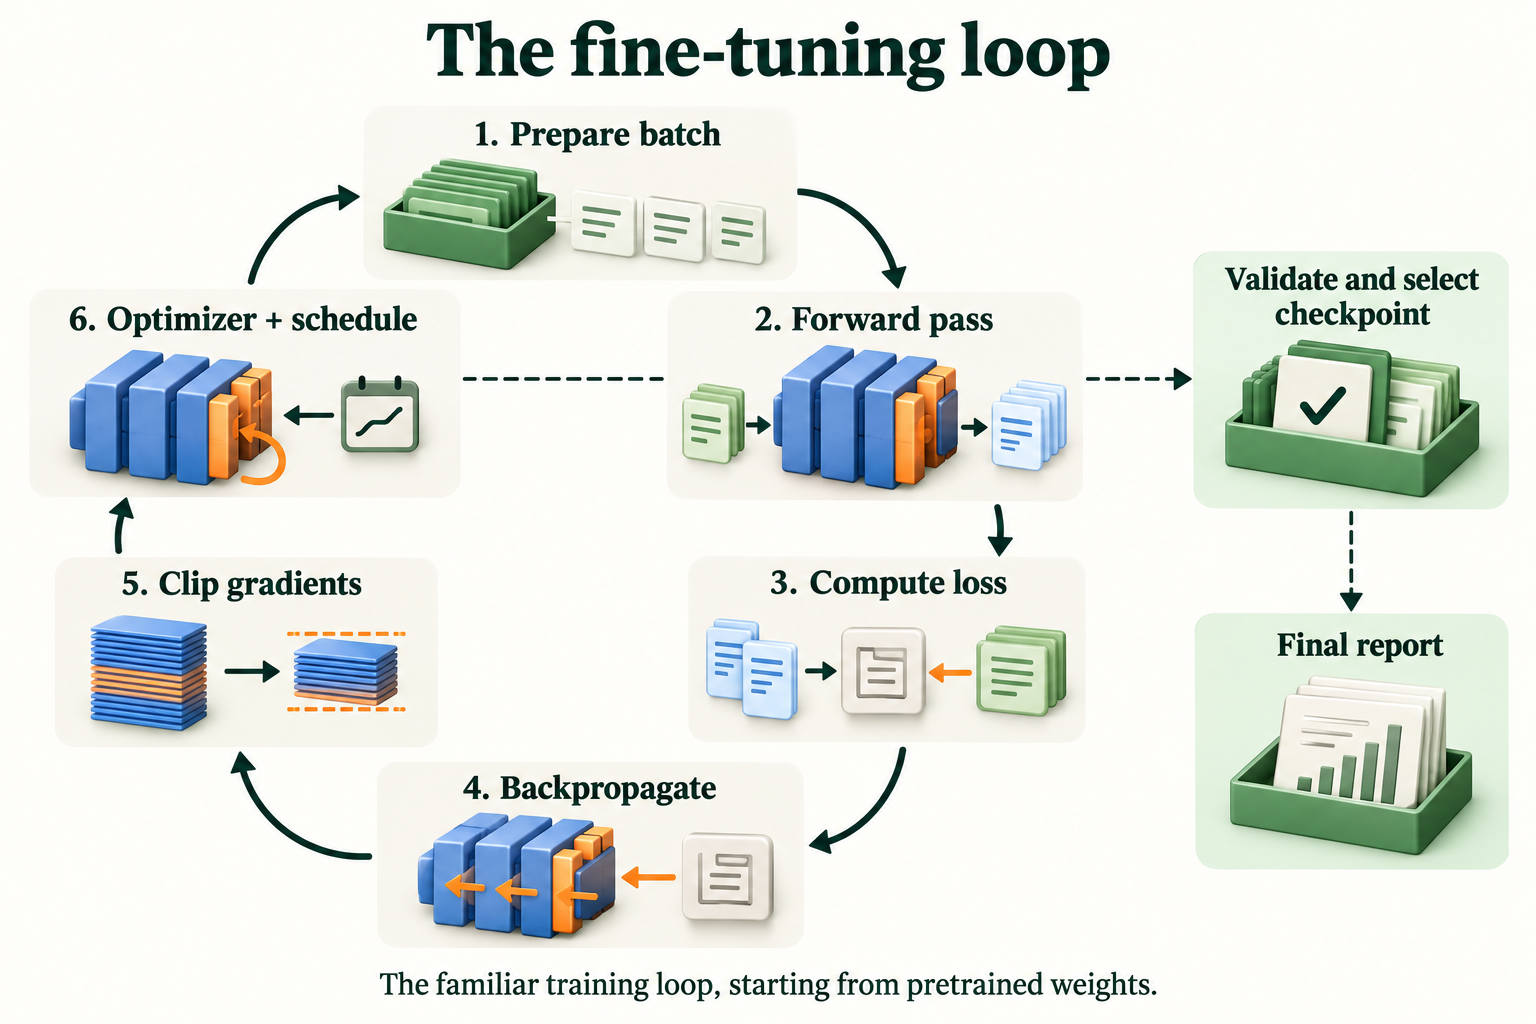

*Figure 8.4.1. Only training batches drive gradients and optimizer updates. Validation selects checkpoints; a declared final test reports the selected setup.*

### The data

The same fixed split and the same 1,000 training reviews as Note 8.3, checked by fingerprint, with head+tail truncation to 128 tokens (Note 8.2). We keep each review as a list of token IDs; a **data collator** pads every batch to its longest member and adds the attention mask.

In [2]:
def load_imdb_split(seed=0, n_val=2500, n_eval=1000, verbose=True):
    """The fixed IMDb split shared by every note in Modules 7 and 8 (built in Note 7.1)."""
    ds = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                      data_files={"train": "plain_text/train-*.parquet",
                                  "test":  "plain_text/test-*.parquet"}, revision=DATASET_REVISIONS.get("stanfordnlp/imdb"))
    def dedup(texts, labels, seen):
        keep = []
        for i, t in enumerate(texts):
            if t not in seen:                              # keep only the first copy of each review
                seen.add(t); keep.append(i)
        return [texts[i] for i in keep], np.array([labels[i] for i in keep])
    tr_x, tr_y = dedup(list(ds["train"]["text"]), list(ds["train"]["label"]), set())
    te_x, te_y = dedup(list(ds["test"]["text"]), list(ds["test"]["label"]), set(tr_x))  # also drops test reviews already in train
    if verbose:
        print(f"official split: {len(ds['train'])} train, {len(ds['test'])} test reviews")
        print(f"duplicates removed: {len(ds['train']) - len(tr_x)} from train, "
              f"{len(ds['test']) - len(te_x)} from test (repeats, or reviews that are also in train)")
    clean = lambda xs: [x.replace("<br />", " ") for x in xs]                         # remove HTML line breaks
    rng = np.random.default_rng(seed)
    p = rng.permutation(len(tr_x)); v, t = p[:n_val], p[n_val:]                       # validation is carved from train
    q = rng.permutation(len(te_x))[:n_eval]                                           # a fixed sample of the test set
    split = {"train": (clean([tr_x[i] for i in t]), tr_y[t]),
             "val":   (clean([tr_x[i] for i in v]), tr_y[v]),
             "test":  (clean(te_x), te_y)}
    split["val_eval"] = (split["val"][0][:n_eval], split["val"][1][:n_eval])
    split["test_eval"] = (clean([te_x[i] for i in q]), te_y[q])
    return split

def fingerprint(texts):
    """A short ID for a set of texts: identical sets give identical fingerprints."""
    return hashlib.sha256("\n".join(sorted(texts)).encode()).hexdigest()[:12]

In [3]:
imdb = load_imdb_split()
for name, (x, y) in imdb.items():
    print(f"{name:<9} {len(x):>6} reviews | positive share {y.mean():.3f} | fingerprint {fingerprint(x)}")
train_x, train_y = imdb["train"][0][:1000], imdb["train"][1][:1000]     # the 1,000 labelled reviews of Module 8
val_x, val_y = imdb["val_eval"]
test_x, test_y = imdb["test_eval"]
print("Module 8 training set fingerprint:", fingerprint(train_x))

official split: 25000 train, 25000 test reviews
duplicates removed: 96 from train, 322 from test (repeats, or reviews that are also in train)
train      22404 reviews | positive share 0.502 | fingerprint fb3a1229f951
val         2500 reviews | positive share 0.492 | fingerprint 07758bc36c9b
test       24678 reviews | positive share 0.503 | fingerprint 429c5557b6d4
val_eval    1000 reviews | positive share 0.495 | fingerprint 9934ffeaac91
test_eval   1000 reviews | positive share 0.515 | fingerprint fc9fa98701bc
Module 8 training set fingerprint: 7b0ca50110ca


In [4]:
BASE = "distilbert/distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(BASE, revision=MODEL_REVISIONS.get(BASE))

def head_tail_ids(texts, max_length=128):
    """Token IDs keeping the first quarter and last three quarters of the budget (built in Note 8.2)."""
    keep = max_length - 2
    out = []
    for ids in tok(texts, add_special_tokens=False)["input_ids"]:
        if len(ids) > keep:
            ids = ids[:keep // 4] + ids[-(keep - keep // 4):]
        out.append([tok.cls_token_id] + ids + [tok.sep_token_id])
    return out

collate = DataCollatorWithPadding(tok)                       # pads each batch to its longest member
def make_batch(ids_list, labels=None):
    rows = [{"input_ids": ids} for ids in ids_list] if labels is None else \
           [{"input_ids": ids, "labels": int(y)} for ids, y in zip(ids_list, labels)]
    return {k: v.to(device) for k, v in collate(rows).items()}

train_ids, val_ids, test_ids = head_tail_ids(train_x), head_tail_ids(val_x), head_tail_ids(test_x)
print("examples:", len(train_ids), len(val_ids), len(test_ids), "| longest:", max(map(len, train_ids)), "tokens")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (544 > 512). Running this sequence through the model will result in indexing errors


examples: 1000 1000 1000 | longest: 128 tokens


## 2. Loading the Model with a Classification Head

`AutoModelForSequenceClassification` loads DistilBERT's pretrained body and adds a classification head (Note 7.1, Section 4). We also give it readable label names, which are saved with the model. The LOAD REPORT that appears is expected. The UNEXPECTED weights are the base model's word-guessing head, which a classifier doesn't use. The MISSING weights are our new head, which starts random.

In [5]:
torch.manual_seed(0)
model = AutoModelForSequenceClassification.from_pretrained(
    BASE, num_labels=2, id2label={0: "NEGATIVE", 1: "POSITIVE"}, label2id={"NEGATIVE": 0, "POSITIVE": 1}, revision=MODEL_REVISIONS.get(BASE)).to(device)
start_body = copy.deepcopy(model.distilbert.state_dict())           # the pretrained body, kept for later comparisons
print(model.pre_classifier, "\n", model.classifier)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,} | trainable: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 18628.93it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=768, bias=True) 
 Linear(in_features=768, out_features=2, bias=True)
parameters: 66,955,010 | trainable: 66,955,010


The head is two layers: `pre_classifier`, 768 → 768, and `classifier`, 768 → 2, one score per label. All 66,955,010 parameters are trainable. That's what makes this *full* fine-tuning: every pretrained weight, not just the head, will be updated.

> **Key terms**
> - **Classification head:** the new layers mapping the body's output to one score per class; here `pre_classifier` and `classifier`.
> - **`num_labels`, `id2label`, `label2id`:** configuration settings for the number of classes and their names, saved with the model.

## 3. Inputs, Labels and Attention Masks

Here is one batch of 4 training reviews, as the model receives it:

In [6]:
batch = make_batch(train_ids[:4], train_y[:4])
for k, v in batch.items():
    print(f"{k:<15} {tuple(v.shape)}  {v[0, :12].tolist() if v.dim() == 2 else v.tolist()}")
print("first review starts:", tok.decode(batch["input_ids"][0, :12]))

input_ids       (4, 128)  [101, 7112, 28740, 1006, 2012, 2484, 1007, 2018, 2525, 2856, 2048, 21688]
labels          (4,)  [1, 0, 1, 0]
attention_mask  (4, 128)  [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
first review starts: [CLS] steven spielberg ( at 24 ) had already directed two superb


Each review becomes 128 token IDs, starting with 101 (`[CLS]`). The attention mask marks real tokens with 1 and padding with 0. The batch is as long as its longest review; any shorter review would be padded with 0s. The labels are plain integers, 1 for positive and 0 for negative. When the batch includes `labels`, the model computes the loss itself.

## 4. The Training Objective and Loss

The objective is the familiar **cross-entropy** loss (Module 2): for each review, take the probability the model gives to the *correct* class, and take minus its logarithm. Averaging over the batch gives the loss. Let's compute it by hand and compare it with the model's own:

In [7]:
model.eval()
with torch.no_grad():
    out = model(**batch)                                             # labels in the batch -> the model computes the loss
logits = out.logits                                                  # (4, 2) raw scores
log_probs = logits.log_softmax(dim=-1)                               # log of softmax probabilities
by_hand = -log_probs[torch.arange(4), batch["labels"]].mean()        # cross-entropy: -log P(correct class), averaged
print("logits:\n", logits.round(decimals=3))
print(f"loss from the model {out.loss.item():.4f} | by hand {by_hand.item():.4f} | ln 2 = {math.log(2):.4f}")

logits:
 tensor([[-0.0650, -0.0850],
        [-0.0080, -0.0560],
        [-0.0580, -0.0530],
        [-0.0550, -0.0690]])
loss from the model 0.6874 | by hand 0.6874 | ln 2 = 0.6931


The new head is random, so its scores (logits) for the two classes are tiny and almost equal: the model has no opinion yet. Our hand-computed loss, 0.6874, matches the model's exactly, and both are close to ln 2 = 0.6931. That's the cross-entropy of a model that gives each of two classes a probability of one half. Checking the starting loss against this value is a quick way to catch bugs before training (Note 6.5 did the same for a language model).

## 5. Forward Pass, Backpropagation and Updates: The Familiar Loop at Scale

One training step is exactly the Module 2 loop: forward pass, loss, `backward()` to compute gradients, then an optimiser step. Two details matter at this scale. We look at the gradient sizes in each part of the model, and we **clip** the overall gradient size at 1 (Module 3, Note 6.4), so one unusual batch can't produce a huge update.

In [8]:
with torch.no_grad():
    before = model(**batch).loss.item()                              # eval mode (no dropout), as in Section 4
model.train()
opt = torch.optim.AdamW(model.parameters(), lr=5e-5)
torch.manual_seed(0)
loss = model(**batch).loss                                           # train mode: dropout on
loss.backward()                                                     # gradients for all 66,955,010 parameters
norms = {}
for n, p in model.named_parameters():
    part = "head" if not n.startswith("distilbert.") else ("embeddings" if ".embeddings." in n else "layer " + n.split(".")[3])
    norms[part] = norms.get(part, 0.0) + p.grad.norm().item() ** 2
for part, sq in norms.items():
    print(f"gradient size, {part:<10} {math.sqrt(sq):.3f}")
total = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)   # cap the overall gradient size at 1
print(f"overall gradient norm before clipping {total.item():.3f}")
opt.step(); opt.zero_grad()
model.eval()
with torch.no_grad():
    print(f"loss on the same 4 reviews (eval mode): before the step {before:.4f} | after {model(**batch).loss.item():.4f}")

gradient size, embeddings 0.134
gradient size, layer 0    0.184
gradient size, layer 1    0.231
gradient size, layer 2    0.299
gradient size, layer 3    0.355
gradient size, layer 4    0.367
gradient size, layer 5    0.451
gradient size, head       1.424
overall gradient norm before clipping 1.639
loss on the same 4 reviews (eval mode): before the step 0.6874 | after 0.6379


The gradients are largest at the head (1.424) and shrink steadily towards the input, from 0.451 in the last Transformer layer to 0.134 at the embeddings. The new, random head has the most to learn; the pretrained layers near the input are already useful and get gentler signals. The overall gradient norm, 1.639, is above 1, so clipping scaled it down for this step. After one step, the loss on the same 4 reviews falls from 0.6874 to 0.6379. That's the whole loop in miniature, repeated 63 times below.

> **Key terms**
> - **Gradient norm:** the overall size of the gradients, as a single number.
> - **Gradient clipping:** scaling the gradients down when their norm exceeds a limit (here 1.0), to prevent unstable updates.
> - **AdamW:** the Adam optimiser with decoupled weight decay; the standard choice for fine-tuning Transformers.

**Visual walkthrough: Separate learning from selection.**

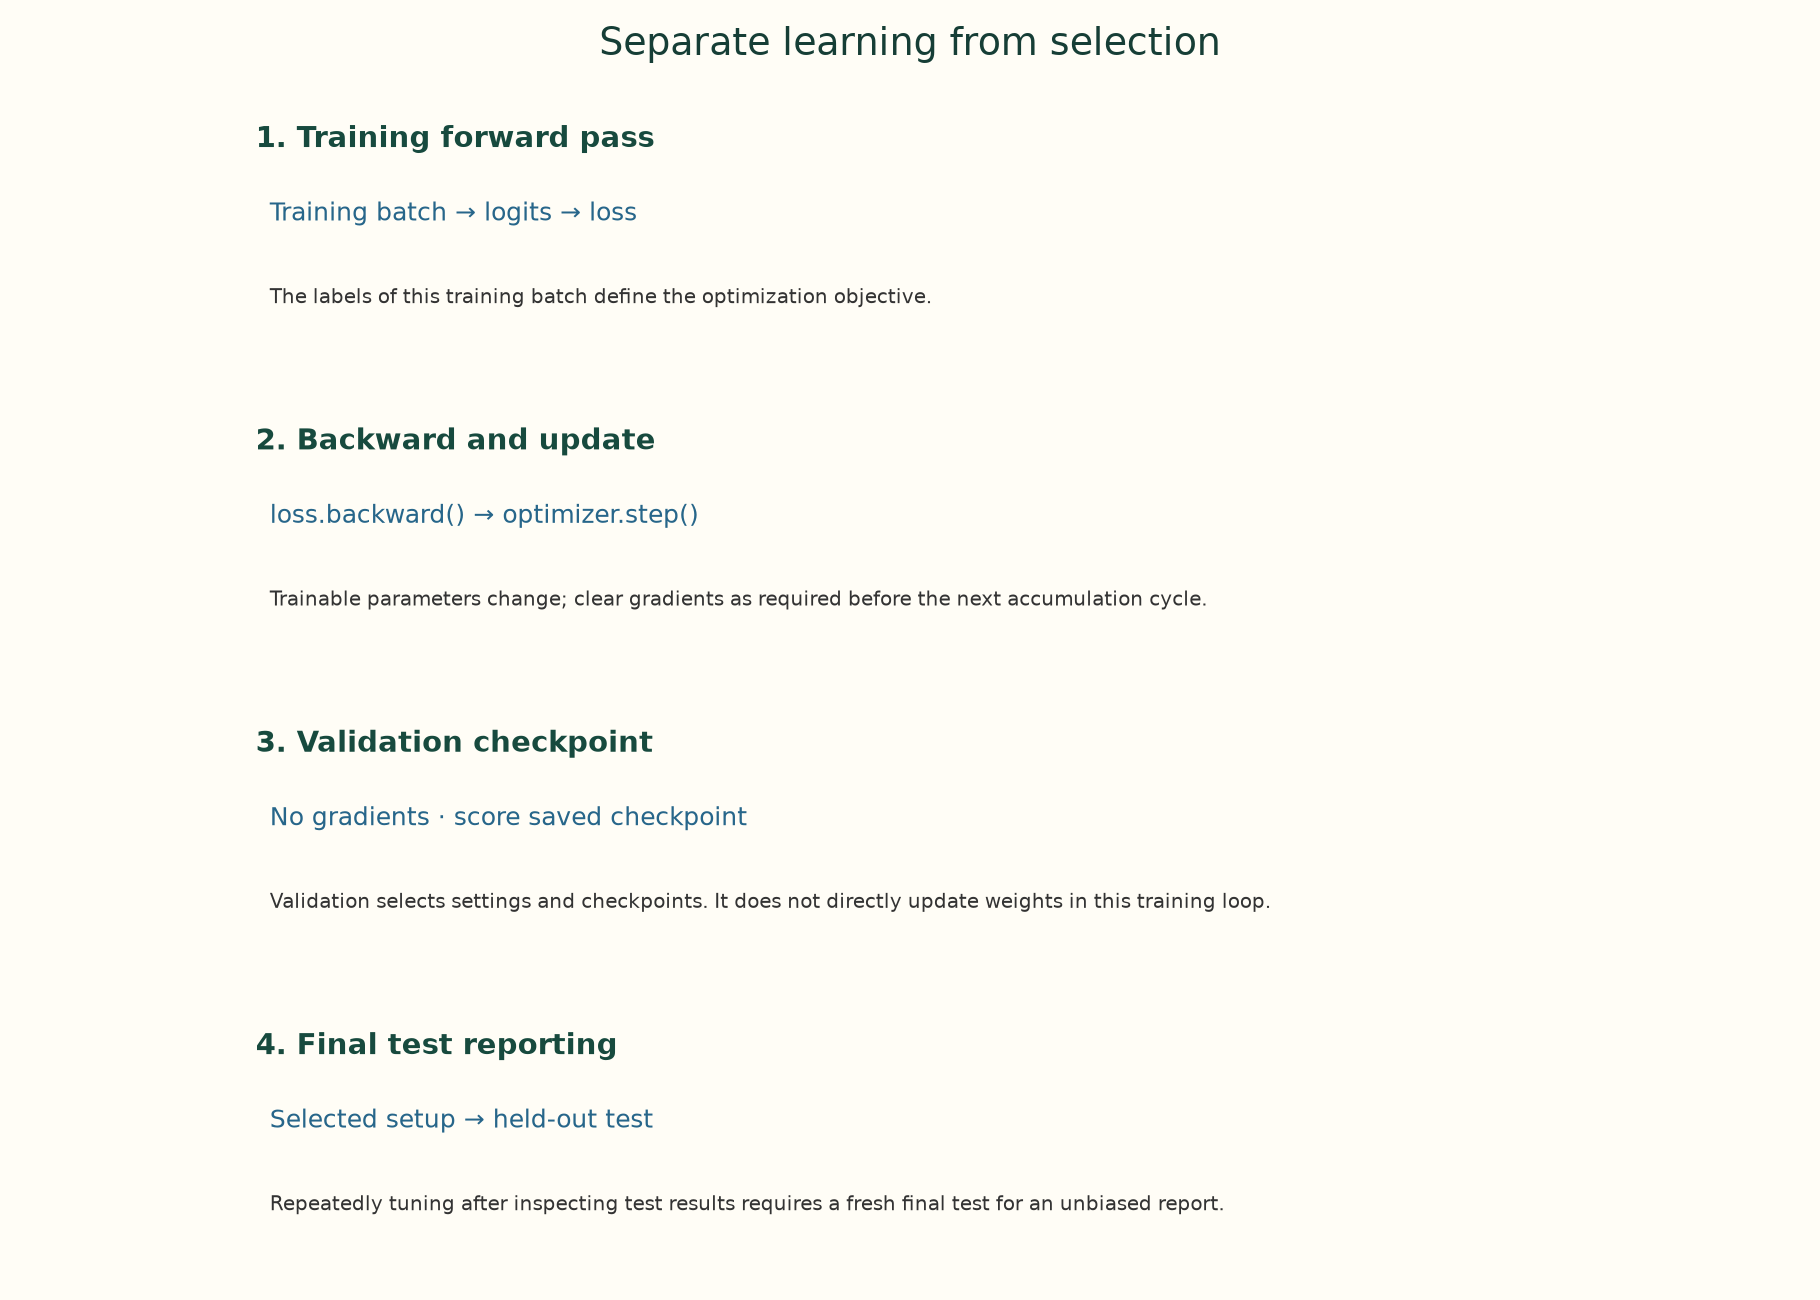

**1. Training forward pass.** Training batch → logits → loss. The labels of this training batch define the optimization objective.

**2. Backward and update.** loss.backward() → optimizer.step(). Trainable parameters change; clear gradients as required before the next accumulation cycle.

**3. Validation checkpoint.** No gradients · score saved checkpoint. Validation selects settings and checkpoints. It does not directly update weights in this training loop.

**4. Final test reporting.** Selected setup → held-out test. Repeatedly tuning after inspecting test results requires a fresh final test for an unbiased report.

*The app adds a paused animation of this same supplied example.*

## 6. Learning Rate (and Why It's Much Smaller), Batch Size, Epochs, Warmup

### 6.1 Why the learning rate is small

When you trained small networks from scratch in Modules 2 and 3, learning rates around 1e-3 were typical. Fine-tuning a pretrained Transformer usually uses something like 1e-5 to 5e-5, twenty or more times smaller. The reason is that the weights are already good: we want to *nudge* them, not overwrite them. Here's how far a single AdamW step moves one of DistilBERT's feed-forward weight matrices at each learning rate:

In [9]:
w = model.distilbert.transformer.layer[0].ffn.lin1.weight
w = w.detach().clone()
for lr in (5e-5, 1e-3):
    probe = copy.deepcopy(model)                                     # a throwaway copy
    o = torch.optim.AdamW(probe.parameters(), lr=lr)
    probe.train(); torch.manual_seed(0)
    probe(**batch).loss.backward(); o.step()
    w1 = probe.distilbert.transformer.layer[0].ffn.lin1.weight
    print(f"lr {lr:g}: one step changes a feed-forward weight matrix by {((w1 - w).norm() / w.norm()).item():.3%} of its size")
del probe

lr 5e-05: one step changes a feed-forward weight matrix by 0.120% of its size


lr 0.001: one step changes a feed-forward weight matrix by 2.402% of its size


At 5e-5, one step changes the matrix by 0.120% of its size; at 1e-3, by 2.402%, twenty times more. Over 63 steps, a large rate would move the pretrained weights far from where pretraining left them, destroying much of what made them valuable (and making forgetting, Note 8.1, much worse). We use **5e-5**.

### 6.2 Batch size, epochs and warmup

- **Batch size 16:** large enough for stable gradients, small enough to be fast on a CPU.
- **One epoch:** one pass over the 1,000 reviews, 63 steps. With a pretrained model, one to three epochs is typical; Note 8.1 showed a small dataset overfitting by the third.
- **Warmup, then linear decay:** the learning rate starts near zero, rises to its peak over the first 10% of steps, then falls steadily to zero. Warmup protects the pretrained body in the first steps, while the random head is still producing large, meaningless gradients.

63 steps | warmup 7 steps | peak learning rate 5e-05


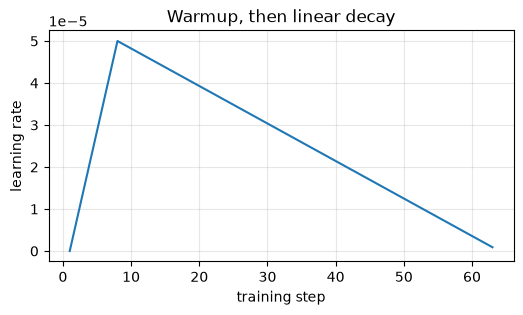

In [10]:
EPOCHS, BATCH, LR, WARMUP = 1, 16, 5e-5, 0.1
steps = EPOCHS * math.ceil(len(train_ids) / BATCH)
dummy = torch.optim.AdamW([torch.zeros(1, requires_grad=True)], lr=LR)
sched = get_linear_schedule_with_warmup(dummy, num_warmup_steps=math.ceil(WARMUP * steps), num_training_steps=steps)
lrs = []
for _ in range(steps):
    lrs.append(sched.get_last_lr()[0]); dummy.step(); sched.step()
print(f"{steps} steps | warmup {math.ceil(WARMUP * steps)} steps | peak learning rate {max(lrs):g}")
plt.figure(figsize=(6, 3)); plt.plot(range(1, steps + 1), lrs)
plt.xlabel("training step"); plt.ylabel("learning rate"); plt.title("Warmup, then linear decay"); plt.grid(alpha=0.3); plt.show()

With 63 steps, warmup lasts 7 steps, the peak learning rate is 5e-05, and the rate decays to zero by the end.

> **Key terms**
> - **Learning rate:** the step size of each update; fine-tuning uses small values (here 5e-5).
> - **Warmup:** gradually raising the learning rate from near zero at the start of training.
> - **Linear decay:** lowering the learning rate steadily to zero by the end of training.
> - **Learning-rate schedule:** the plan for how the learning rate changes over training.

**Check yourself.**

1. Why is warmup especially useful when fine-tuning a pretrained body with a *new, random* head?

<details>
<summary>Worked answer</summary>

At the start, the head's weights are random, so its outputs are meaningless and the gradients flowing back from it can be large and erratic. With a full learning rate from step one, those erratic gradients would push the carefully pretrained body around before the head has learned anything sensible. Warmup keeps the early steps tiny, so the head can settle first, then lets the learning rate rise once the gradients carry real information.

</details>

## 7. Validation and Checkpoint Selection

The model after the last step isn't necessarily the best one. Training can overshoot or start to overfit, and on small data the validation score wobbles. So we evaluate during training and keep the best **checkpoint**: a copy of the weights at that moment.

To keep evaluation cheap during training, we check every 16 steps on the first 200 validation reviews, and keep the checkpoint with the best accuracy. That is a choice made on validation, never on test. After training we restore it and measure it on all 1,000 validation reviews. The helper below returns P(positive) for a list of reviews.

In [11]:
def predict(m, ids_list, batch_size=64):
    m.eval(); out = []
    order = np.argsort([len(x) for x in ids_list])                    # similar lengths together
    probs = np.empty(len(ids_list))
    with torch.inference_mode():
        for i in range(0, len(ids_list), batch_size):
            idx = order[i:i + batch_size]
            probs[idx] = m(**make_batch([ids_list[j] for j in idx])).logits.softmax(-1)[:, 1].cpu().numpy()
    return probs                                                       # P(positive) per review

check_ids, check_y = val_ids[:200], val_y[:200]                      # a small validation set for checkpoints

## 8. Practice: A Custom PyTorch Loop, Then the Hugging Face Trainer

### 8.1 The custom loop

Here is the complete loop: AdamW, the warmup-then-decay schedule, gradient clipping, and a checkpoint check every 16 steps. We start from a freshly loaded model, with the same seed for the new head.

In [12]:
torch.manual_seed(0)
model = AutoModelForSequenceClassification.from_pretrained(BASE, num_labels=2,
            id2label={0: "NEGATIVE", 1: "POSITIVE"}, label2id={"NEGATIVE": 0, "POSITIVE": 1}, revision=MODEL_REVISIONS.get(BASE)).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=LR)
sched = get_linear_schedule_with_warmup(opt, num_warmup_steps=math.ceil(WARMUP * steps), num_training_steps=steps)
g = torch.Generator().manual_seed(0)
log, checkpoints, best = [], [], (-1, None, None)
t0 = benchmark_clock()
step = 0
for epoch in range(EPOCHS):
    for b in torch.randperm(len(train_ids), generator=g).split(BATCH):
        model.train()
        loss = model(**make_batch([train_ids[i] for i in b], train_y[b.numpy()])).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(); opt.zero_grad()
        step += 1
        log.append((step, loss.item()))
        if step % 16 == 0 or step == steps:                          # checkpoint: evaluate on 200 validation reviews
            acc = ((predict(model, check_ids) > 0.5) == check_y).mean()
            checkpoints.append((step, acc))
            print(f"step {step:>2}: training loss (last 16 steps) {np.mean([l for _, l in log[-16:]]):.3f} | validation accuracy {acc:.3f}")
            if acc > best[0]:
                best = (acc, step, copy.deepcopy(model.state_dict()))
loop_secs = benchmark_clock() - t0
print(f"training took {loop_secs:.0f} s | best checkpoint: step {best[1]} (validation accuracy {best[0]:.3f})")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 15389.68it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


step 16: training loss (last 16 steps) 0.671 | validation accuracy 0.475


step 32: training loss (last 16 steps) 0.567 | validation accuracy 0.840


step 48: training loss (last 16 steps) 0.426 | validation accuracy 0.865


step 63: training loss (last 16 steps) 0.425 | validation accuracy 0.845
training took 58 s | best checkpoint: step 48 (validation accuracy 0.865)


At step 16, the model still knows nothing useful: validation accuracy is 0.475, below chance. Then it learns fast: 0.840 at step 32 and 0.865 at step 48, the best checkpoint, before slipping to 0.845 at the last step. The plot shows the two views:

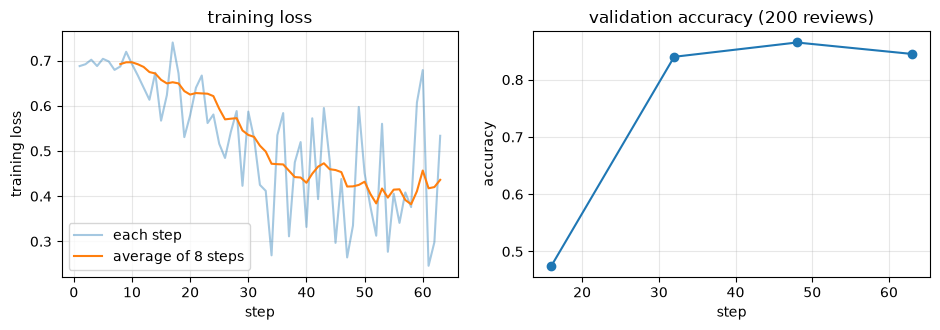

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
s_, l_ = zip(*log)
axes[0].plot(s_, l_, alpha=0.4, label="each step")
axes[0].plot(s_[7:], np.convolve(l_, np.ones(8) / 8, mode="valid"), label="average of 8 steps")
axes[0].set_xlabel("step"); axes[0].set_ylabel("training loss"); axes[0].legend(); axes[0].set_title("training loss")
cs, ca = zip(*checkpoints)
axes[1].plot(cs, ca, "o-"); axes[1].set_xlabel("step"); axes[1].set_ylabel("accuracy"); axes[1].set_title("validation accuracy (200 reviews)")
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The training loss jumps around from step to step, because each batch has only 16 reviews, but its moving average falls steadily: the printed 16-step averages go from 0.671 to 0.425. Validation accuracy rises quickly and then levels off, and the last checkpoint is slightly worse than the one at step 48. That's why we select rather than simply taking the end. We restore the best checkpoint and measure it on the full validation set:

In [14]:
model.load_state_dict(best[2])                                          # restore the chosen checkpoint
loop_val_p = predict(model, val_ids)
print(f"custom loop, chosen checkpoint (step {best[1]}): accuracy on the full validation set (1,000) {((loop_val_p > 0.5) == val_y).mean():.3f}")

custom loop, chosen checkpoint (step 48): accuracy on the full validation set (1,000) 0.860


The chosen checkpoint scores 0.860 on the 1,000 validation reviews.

### 8.2 The same recipe with the `Trainer`

Hugging Face's `Trainer` runs this same loop for you. You describe the recipe in `TrainingArguments` (batch size, epochs, learning rate, warmup, schedule, clipping), and `Trainer` handles batching, the optimiser, the schedule, logging, devices and, if asked, saving and evaluation. Two details for this library version:
- `warmup_steps` accepts a fraction, so 0.1 means 10% of all steps.
- `use_cpu` must be set explicitly on a CPU-only run. On a Mac, `Trainer` would otherwise pick the Apple GPU by itself (Note 7.4 met the same behaviour in pipelines).

In [15]:
train_ds = Dataset.from_dict({"input_ids": train_ids, "labels": [int(v) for v in train_y]})
args = TrainingArguments(
    output_dir="data/trainer-run",
    per_device_train_batch_size=BATCH, num_train_epochs=EPOCHS,
    learning_rate=LR, warmup_steps=WARMUP,                 # a value below 1 means a fraction of all steps
    lr_scheduler_type="linear", max_grad_norm=1.0,         # same schedule and clipping as our loop
    logging_steps=16, save_strategy="no", report_to="none", seed=0,
    use_cpu=(device == "cpu"),                             # without this, a Mac may silently use its GPU
)
torch.manual_seed(0)
tr_model = AutoModelForSequenceClassification.from_pretrained(BASE, num_labels=2,
               id2label={0: "NEGATIVE", 1: "POSITIVE"}, label2id={"NEGATIVE": 0, "POSITIVE": 1}, revision=MODEL_REVISIONS.get(BASE))
trainer = Trainer(model=tr_model, args=args, train_dataset=train_ds, data_collator=collate)
t0 = benchmark_clock()
trainer.train()
trainer_secs = benchmark_clock() - t0
print(f"Trainer took {trainer_secs:.0f} s | device: {args.device}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 13222.07it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
16,0.673569
32,0.557496
48,0.396144


Trainer took 48 s | device: cpu


In [16]:
print("Trainer's logged training loss:", [(h["step"], round(h["loss"], 3)) for h in trainer.state.log_history if "loss" in h])
trainer_val_p = predict(trainer.model.to(device), val_ids)
print(f"validation accuracy (1,000): Trainer {((trainer_val_p > 0.5) == val_y).mean():.3f} | custom loop, chosen checkpoint {((loop_val_p > 0.5) == val_y).mean():.3f}")
same = ((trainer_val_p > 0.5) == (loop_val_p > 0.5)).mean()
print(f"Trainer and our chosen checkpoint give the same label on {same:.1%} of validation reviews")
del trainer, tr_model

Trainer's logged training loss: [(16, 0.674), (32, 0.557), (48, 0.396)]


validation accuracy (1,000): Trainer 0.870 | custom loop, chosen checkpoint 0.860
Trainer and our chosen checkpoint give the same label on 90.4% of validation reviews


The `Trainer` ran on the CPU, as intended. Its logged training loss follows the same path as our loop's (0.674, 0.557, 0.396 at steps 16, 32 and 48), and its final model scores 0.870 on validation, against 0.860 for our chosen checkpoint. The two models agree on 90.4% of validation reviews. They aren't identical, because the batches are shuffled differently and dropout draws different random numbers, but the recipe gives the same quality. A difference of 0.010 on 1,000 reviews is ten reviews in these runs. Repeated runs and a paired uncertainty analysis are needed before claiming the recipes have equivalent quality.

So which should you use? Write the loop yourself when you're learning or need unusual control (custom losses, special sampling). Use `Trainer` for standard jobs: it is less code and fewer chances for bugs, and it brings logging, checkpointing, mixed precision and multi-GPU training for free.

> **Key terms**
> - **Checkpoint selection:** keeping the weights from the training moment with the best validation score.
> - **`Trainer` / `TrainingArguments`:** Hugging Face's ready-made training loop and its settings.

> **Common mistake:** letting `Trainer` (or a pipeline) choose the device on its own. On a Mac it may silently train on the Apple GPU, and on a machine with a GPU it will use it even if you intended a CPU comparison. Set the device explicitly when it matters.

**Check yourself.**

1. Our loop kept the checkpoint from step 48 rather than the final one at step 63. Why is it important that this choice was made on the 200 *validation* reviews and not on test?

<details>
<summary>Worked answer</summary>

Choosing among checkpoints is a form of tuning: the chosen one is partly the luckiest on the data used to choose. If that data were the test set, the test score would include that luck and overstate how the model will do on new reviews. Choosing on validation keeps the test set untouched, so its single score stays an honest estimate.

</details>

## 9. Saving and Reloading the Fine-Tuned Model

### 9.1 Save and reload

We save the chosen checkpoint and its tokeniser together (Note 7.4), reload them, and check that nothing changed:

In [17]:
save_dir = "data/distilbert-imdb-full"
model.save_pretrained(save_dir); tok.save_pretrained(save_dir)
size = sum(os.path.getsize(os.path.join(save_dir, f)) for f in os.listdir(save_dir))
reloaded = AutoModelForSequenceClassification.from_pretrained(save_dir, revision=MODEL_REVISIONS.get(save_dir)).to(device)
probe_ids = val_ids[:16]
print(f"saved {sorted(os.listdir(save_dir))} | {size / 1e6:.1f} MB")
print("reloaded model gives identical probabilities:", np.array_equal(predict(model, probe_ids), predict(reloaded, probe_ids)))
print("labels stored with the model:", reloaded.config.id2label)
shutil.rmtree(save_dir); del reloaded

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 16.66it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 17765.96it/s]

saved ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json'] | 268.5 MB


reloaded model gives identical probabilities: True
labels stored with the model: {0: 'NEGATIVE', 1: 'POSITIVE'}


The folder holds the configuration, the weights (268.5 MB in total) and the tokeniser. The reloaded model gives identical probabilities, and the label names travelled with it: `{0: 'NEGATIVE', 1: 'POSITIVE'}`. We then delete the copy, since every task fine-tuned this way needs its own full-size copy, a cost Note 8.5 avoids.

### 9.2 One look at the test set

All choices are made, so we use the test set once:

In [18]:
test_p = predict(model, test_ids)                                       # the test set, used once
test_pred = (test_p > 0.5).astype(int)
tp, fp, fn = ((test_pred == 1) & (test_y == 1)).sum(), ((test_pred == 1) & (test_y == 0)).sum(), ((test_pred == 0) & (test_y == 1)).sum()
test_metrics = {"accuracy": round(float((test_pred == test_y).mean()), 4),
                "recall_neg": round(float(((test_pred == 0) & (test_y == 0)).sum() / (test_y == 0).sum()), 4),
                "recall_pos": round(float(tp / (test_y == 1).sum()), 4),
                "f1_pos": round(float(2 * tp / (2 * tp + fp + fn)), 4)}
print("test (1,000 reviews):", test_metrics)

test (1,000 reviews): {'accuracy': 0.834, 'recall_neg': 0.8742, 'recall_pos': 0.7961, 'f1_pos': 0.8316}


The fine-tuned model scores 0.834 on the 1,000 test reviews, with recall 0.8742 on negative reviews and 0.7961 on positive ones.

How does that compare with the baselines? Note 8.3 saved each baseline's prediction for every test review, so we can compare on exactly the same reviews with paired sign tests:

In [19]:
ensure_comparison_results(["8.3"])
from scipy.stats import binomtest
if os.path.exists("results/8.3.json"):                                  # written by Note 8.3
    base = json.load(open("results/8.3.json"))
    assert base["split_fingerprints"]["test_eval"] == fingerprint(test_x), "different test reviews: rerun Note 8.3"
    for name, r in base["rungs"].items():
        other = np.array(r["test_pred"])
        a = int(((test_pred == test_y) & (other != test_y)).sum()); b = int(((test_pred != test_y) & (other == test_y)).sum())
        print(f"vs {name:<40} test {r['test']['accuracy']:.3f} | only fine-tuned right {a:>3} | only baseline right {b:>3} | p = {(binomtest(a, a + b).pvalue if a + b else 1.0):.2g}")
else:
    print("results/8.3.json not found: run Note 8.3 first to compare with the baselines")

vs majority class                           test 0.485 | only fine-tuned right 410 | only baseline right  61 | p = 1.5e-64
vs TF-IDF, 1,000 labels                     test 0.828 | only fine-tuned right 105 | only baseline right  99 | p = 0.73
vs TF-IDF, all labels                       test 0.913 | only fine-tuned right  45 | only baseline right 124 | p = 9.8e-10
vs SST-2 model, off the shelf               test 0.873 | only fine-tuned right  50 | only baseline right  89 | p = 0.0012
vs frozen DistilBERT + logistic regression  test 0.837 | only fine-tuned right  78 | only baseline right  81 | p = 0.87


This is the honest result of the workflow.
- **Fine-tuning clearly learned the task:** it beats the majority-class floor overwhelmingly.
- **It is statistically not significantly different in this paired comparison from the two cheaper 1,000-label baselines:** TF-IDF (105 against 99, p = 0.73) and the frozen encoder with a linear head (78 against 81, p = 0.87).
- **It is significantly worse than the off-the-shelf SST-2 model** (50 against 89, p = 0.0012), **and than TF-IDF with all labels.**

With 1,000 labels, one epoch and 128 tokens, updating all 66,955,010 weights bought nothing over training only a linear head on frozen features (Note 8.3), and less than a model someone else had already adapted on a large sentiment dataset. That's not a failure of the workflow, which ran correctly, but a measured answer to "is fine-tuning worth it *here*?" Note 8.5 asks the same question of a much cheaper method, and Note 8.7 makes the decision.

### 9.3 What it cost the model's old skills

Finally, Note 8.1's forgetting measure: the word-guessing loss of the original masked-language head on 200 held-out reviews, with the pretrained body and with our fine-tuned body.

In [20]:
mlm = AutoModelForMaskedLM.from_pretrained(BASE, revision=MODEL_REVISIONS.get(BASE)).to(device).eval()      # Note 8.1's forgetting measure
held = imdb["val"][0][1000:1200]
enc = tok(held, truncation=True, max_length=128, padding=True, return_tensors="pt")
gm = torch.Generator().manual_seed(0)
special = (enc["input_ids"] == tok.cls_token_id) | (enc["input_ids"] == tok.sep_token_id) | (enc["attention_mask"] == 0)
hide = (torch.rand(enc["input_ids"].shape, generator=gm) < 0.15) & ~special
masked_ids = enc["input_ids"].clone(); masked_ids[hide] = tok.mask_token_id
targets = enc["input_ids"].clone(); targets[~hide] = -100
def word_guessing_loss(body_state):
    mlm.distilbert.load_state_dict(body_state)                         # swap in a body, keep the word-guessing head
    with torch.inference_mode():
        return mlm(input_ids=masked_ids.to(device), attention_mask=enc["attention_mask"].to(device), labels=targets.to(device)).loss.item()
forget = {"pretrained": round(word_guessing_loss(start_body), 3), "fine-tuned": round(word_guessing_loss(model.distilbert.state_dict()), 3)}
print("word-guessing loss on 200 held-out reviews:", forget)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 12370.49it/s]

word-guessing loss on 200 held-out reviews: {'pretrained': 3.381, 'fine-tuned': 4.07}


The loss rises from 3.381 to 4.07. Full fine-tuning on 1,000 reviews has measurably degraded the pretrained skill, even with a small learning rate and a single epoch.

Everything is saved for Note 8.7: settings, costs (including a memory estimate of weights, gradients and two Adam states in float32, which Note 8.5 explains), validation and test results, test predictions, the forgetting measure, the loss curve and the checkpoint scores.

> **Interpret the evidence carefully.** The retention comparison uses the same tied-output setup explained in 8.1. A loss increase here is evidence of reduced performance on this specific probe, not a comprehensive measure of catastrophic forgetting.

In [21]:
n_params = sum(p.numel() for p in model.parameters())
os.makedirs("results", exist_ok=True)
record = {
    "note": "8.4", "method": "full fine-tuning (custom loop, chosen checkpoint)",
    "split_fingerprints": {k: fingerprint(imdb[k][0]) for k in ("train", "val_eval", "test_eval")},
    "train_subset_fingerprint": fingerprint(train_x),
    "settings": {"model": BASE, "max_length": 128, "truncation": "head+tail", "epochs": EPOCHS, "batch_size": BATCH,
                 "learning_rate": LR, "warmup": WARMUP, "grad_clip": 1.0, "chosen_step": int(best[1])},
    "labels_used": 1000, "trainable_parameters": n_params,
    "train_time": f"{loop_secs:.0f} s",
    "training_memory_estimate_mb": round(n_params * 4 * 4 / 1e6),      # weights + gradients + 2 Adam states, float32
    "val": {"accuracy": round(float(((loop_val_p > 0.5) == val_y).mean()), 4)},
    "test": test_metrics, "test_pred": test_pred.tolist(),
    "forgetting_word_guessing_loss": forget,
    "train_loss_curve": [(s, round(l, 4)) for s, l in log],
    "val_checkpoints": [(s, round(float(a), 4)) for s, a in checkpoints],
    "trainer": {"val_accuracy": round(float(((trainer_val_p > 0.5) == val_y).mean()), 4), "train_time": f"{trainer_secs:.0f} s"},
}
record['ordered_test_fingerprint'] = ordered_fingerprint(test_x, test_y)
record['artifact_origin'] = 'learner execution of this notebook'
record['model_revisions'] = MODEL_REVISIONS
record['dataset_revisions'] = DATASET_REVISIONS
with open("results/8.4.json", "w") as f:
    json.dump(record, f, indent=1)
print("wrote results/8.4.json")

wrote results/8.4.json


> **Common mistake:** reporting the best of several checkpoints by their *test* scores, or tuning until the test number looks good. Choose everything on validation, test once, and report what you get, even when, as here, it's not the result you hoped for.

**Check yourself.**

1. The fine-tuned model and TF-IDF scored 0.834 and 0.828 on test. Why isn't it enough to say "fine-tuning is better by 0.006"?

<details>
<summary>Worked answer</summary>

Because 0.006 on 1,000 reviews is six reviews, easily within the variation you'd see from a different test sample or a different training run. The paired sign test on the same reviews showed 105 reviews where only fine-tuning was right and 99 where only TF-IDF was right (p = 0.73), so there's no evidence of a real difference. Quote differences together with a test like this, not on their own.

</details>

## Putting It All Together

Let's reassemble the workflow.

We loaded DistilBERT with a new **classification head** (the LOAD REPORT listed the new head as MISSING and the unused word-guessing head as UNEXPECTED), making all 66,955,010 parameters trainable. A **batch** carried 128-token head+tail inputs, an attention mask and labels. The **loss** at the start, 0.6874 by hand and by the model, matched ln 2, the sign of a correct, untrained setup. One **step** showed gradients largest at the new head (1.424) and smallest at the embeddings (0.134), with clipping limiting the overall size. A small **learning rate** matters: one step at 1e-3 moved a weight matrix twenty times further than at 5e-5. Over 63 steps with **warmup and linear decay**, validation accuracy on 200 reviews rose from 0.475 to 0.865 at step 48, the **checkpoint** we kept. It scored 0.860 on all 1,000 validation reviews. The **`Trainer`** ran the same recipe in a few lines and reached 0.870, agreeing with our model on 90.4% of reviews. The saved model **reloaded** with identical outputs.

The single **test** run gave 0.834, not significantly different from TF-IDF and frozen features on the same 1,000 labels, and significantly below the off-the-shelf SST-2 model (p = 0.0012). And full fine-tuning **cost** the model some of its pretrained skill: word-guessing loss 3.381 → 4.07.

| Quantity | Value |
|---|---|
| Trainable parameters | 66,955,010 |
| Training | 1,000 reviews, 1 epoch, 63 steps, batch 16, lr 5e-5, warmup 7 steps, clipping 1.0 |
| Chosen checkpoint | step 48: validation 0.865 (200) / 0.860 (1,000) |
| `Trainer`, same recipe | validation 0.870 |
| Test (1,000) | 0.834 (recall 0.8742 negative, 0.7961 positive) |
| vs SST-2 off the shelf | worse, p = 0.0012 |
| vs TF-IDF / frozen encoder (1,000 labels) | no significant difference (p = 0.73 / 0.87) |
| Forgetting (word-guessing loss) | 3.381 → 4.07 |

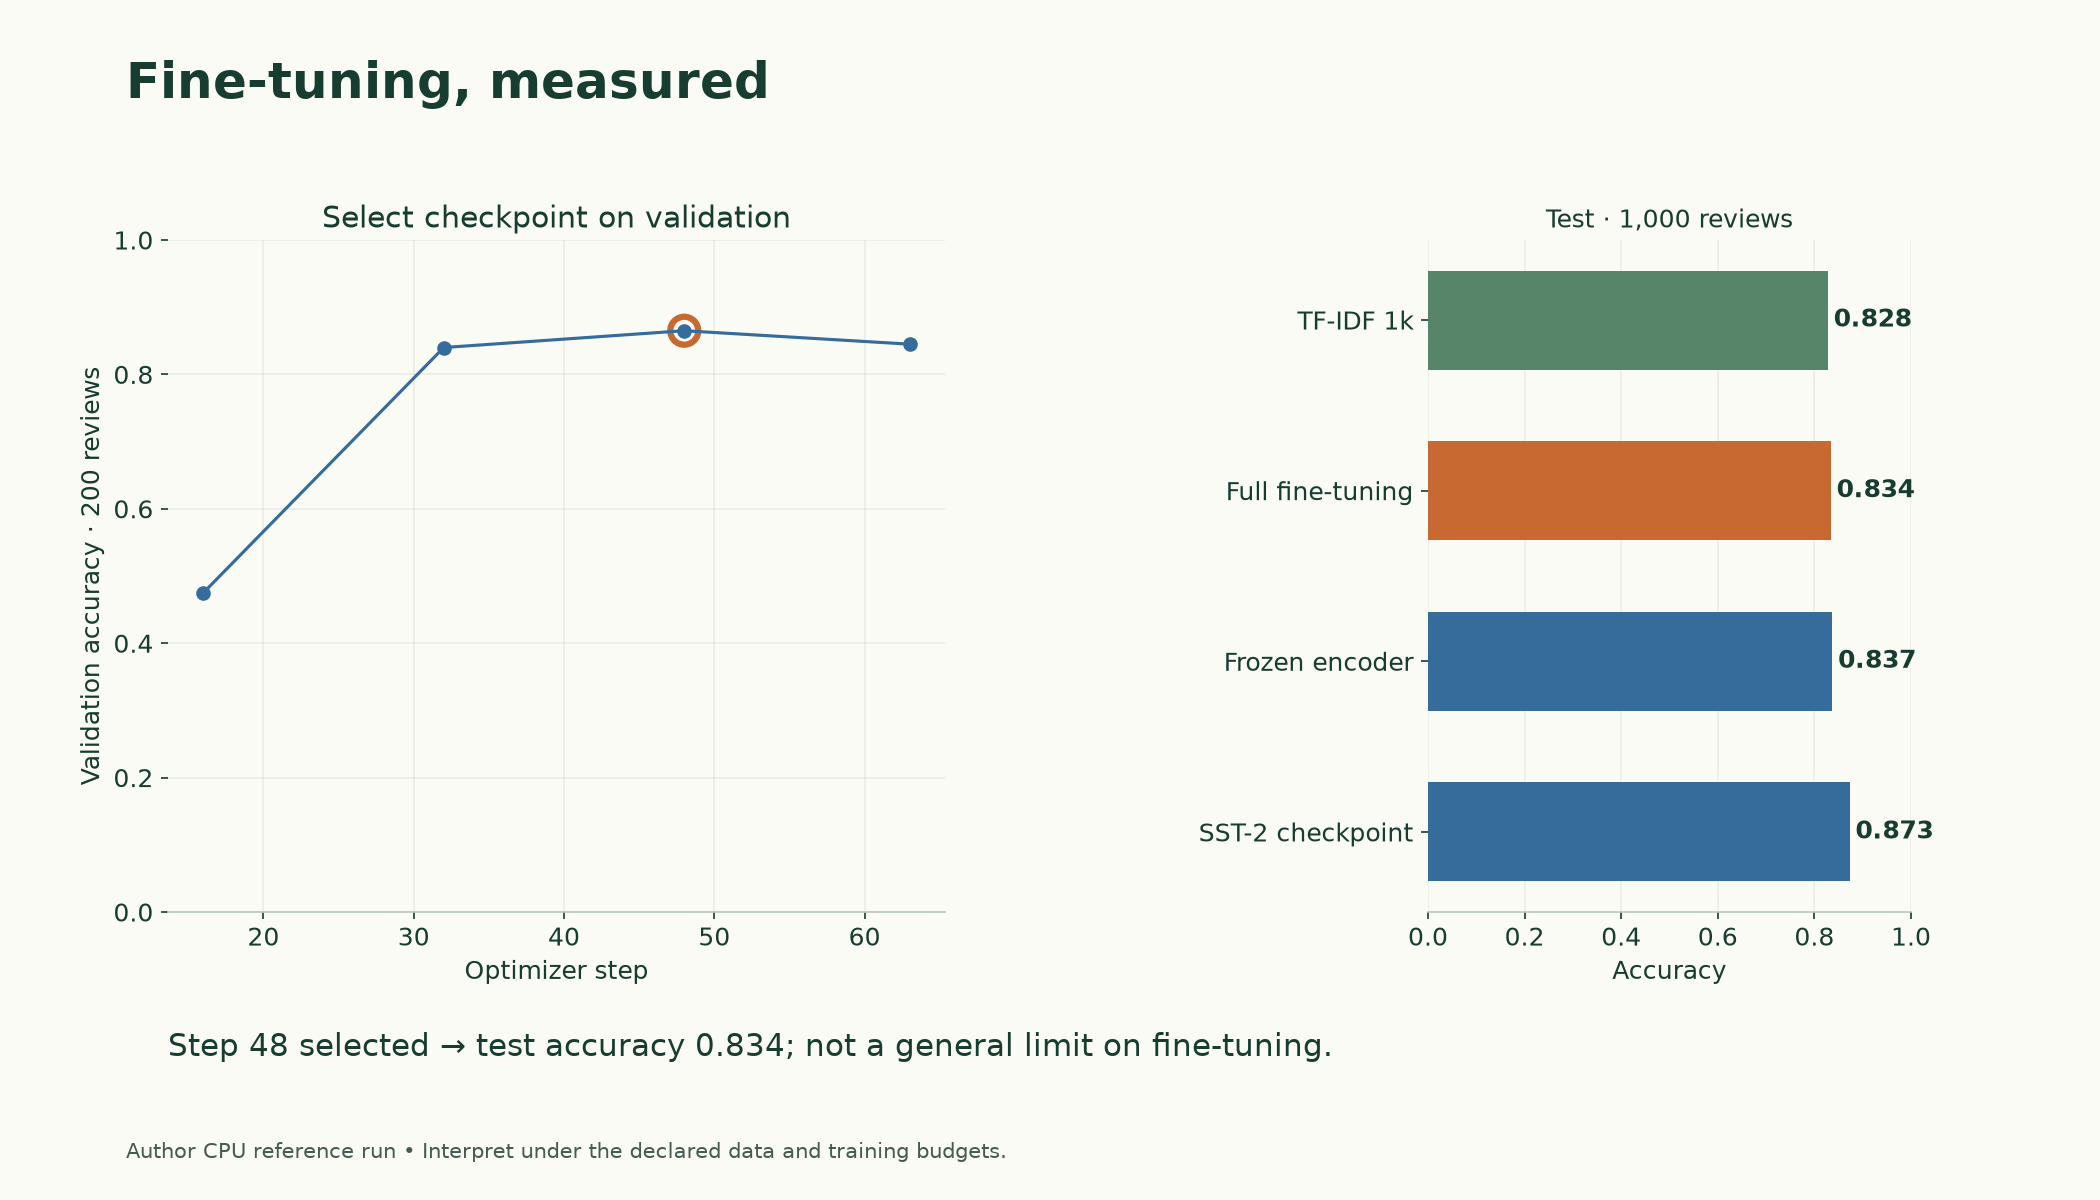

*Figure 8.4.2. Source CPU reference run: the custom-loop checkpoint was chosen on 200 validation reviews and then reported on 1,000 test reviews. The small experiment is not an optimised comparison of all training recipes.*

## Summary

- Fine-tuning a classifier is the familiar training loop applied to a pretrained body with a new **classification head**; all 66,955,010 parameters were trainable.
- The starting **cross-entropy loss** (0.6874) matched our hand computation and was close to ln 2, as expected for an untrained head.
- **Gradients** were largest at the new head (1.424) and smallest at the embeddings (0.134); **clipping** at 1.0 limited the overall step.
- Fine-tuning uses **small learning rates**: one step at 1e-3 moved a weight matrix 2.402% of its size, against 0.120% at 5e-5.
- **Warmup then linear decay** over 63 steps (7 warmup steps, peak 5e-5) protected the pretrained body early in training.
- **Checkpoint selection** on 200 validation reviews kept step 48 (0.865), which scored 0.860 on all 1,000 validation reviews; the last step was slightly worse.
- The **`Trainer`** ran the same recipe (with `use_cpu` set explicitly) and reached 0.870 on validation, agreeing with our model on 90.4% of reviews.
- **`save_pretrained`/`from_pretrained`** reloaded the model with identical outputs and its label names.
- **Test (once):** 0.834. Paired sign tests showed no significant difference from TF-IDF or frozen features with the same 1,000 labels, and a significant gap below the off-the-shelf SST-2 model (p = 0.0012).
- **Forgetting:** word-guessing loss rose from 3.381 to 4.07. Results are saved to `results/8.4.json` for Note 8.7.

## Glossary

| Term | Meaning |
|---|---|
| Full fine-tuning | Updating every weight of a pretrained model on task data. |
| Classification head | New layers mapping the body's output to class scores. |
| `num_labels` / `id2label` / `label2id` | Configuration settings for the number of classes and their names. |
| Cross-entropy loss | Minus the log-probability of the correct class, averaged over a batch. |
| Gradient norm | The overall size of all gradients, as one number. |
| Gradient clipping | Scaling gradients down when their norm exceeds a limit. |
| AdamW | Adam with decoupled weight decay; the standard fine-tuning optimiser. |
| Learning rate | The step size of each update. |
| Warmup | Raising the learning rate gradually at the start of training. |
| Linear decay | Lowering the learning rate steadily to zero. |
| Learning-rate schedule | How the learning rate changes over training. |
| Epoch | One pass over all training examples. |
| Step | One update, made from one batch. |
| Checkpoint | A saved copy of the weights at one moment in training. |
| Checkpoint selection | Keeping the checkpoint with the best validation score. |
| Data collator | A function that pads examples into a batch and builds the attention mask. |
| `Trainer` / `TrainingArguments` | Hugging Face's ready-made training loop and its settings. |